# 05 · Purified density matrices and Kraus-map integration (Secs. IV–V, Figs. 7–9)

The solver never stores $\rho$. It stores a purification $\Psi$ with $\rho=\Psi\Psi^\dagger$ (Eq. 37), whose extra index $\mu$ has dimension $\chi_\mu\sim 1/\mathrm{Tr}\rho^2$.

This notebook works on dense $\Psi\in\mathbb C^{D\times\chi_\mu}$ so every step is visible; the tensor-network version replaces each matrix product by MPO·(comb) and each concatenation by the block constructions of Eqs. 43–45.

In [1]:
import os, sys
from tutorial_utils import *
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(backend_banner())
PAPER_SIZE = HAVE_QTTLIND and os.environ.get("QTTLIND_PAPER_SIZE") == "1"   # published sizes (hours); default: quick mode

qttlind 2.0.0, QTT solver: quick mode (set QTTLIND_PAPER_SIZE=1 for the published sizes).


## 1. Purification, purity and $\chi_\mu$

In [2]:
rng = np.random.default_rng(0)
D = 12
p = np.array([0.90, 0.07, 0.03])                      # a weakly mixed state of rank 3
Q, _ = np.linalg.qr(rng.normal(size=(D, 3)) + 1j * rng.normal(size=(D, 3)))
rho = (Q * p) @ Q.conj().T
w, V = np.linalg.eigh(rho)
Psi = V[:, w > 1e-14] * np.sqrt(w[w > 1e-14])          # rho = Psi Psi^dagger
st = dr.Purified(Psi)
print("||Psi Psi^dag - rho|| =", np.linalg.norm(st.rho() - rho))
print("purity from Psi (||Psi^dag Psi||_F^2):", st.purity(), " exact:", np.trace(rho @ rho).real)
print("chi_mu =", st.chi_mu, "   1/purity =", 1 / st.purity())

||Psi Psi^dag - rho|| = 3.3311239700898104e-16
purity from Psi (||Psi^dag Psi||_F^2): 0.8158000000000004  exact: 0.8157999999999999
chi_mu = 3    1/purity = 1.2257906349595482


## 2. Vector addition versus matrix addition (Eqs. 40–45, Fig. 9)

* **Vector addition** $\Psi_1+\Psi_2$ keeps $\chi_\mu$ and produces $(\Psi_1+\Psi_2)(\Psi_1+\Psi_2)^\dagger$, with cross terms.
* **Matrix addition** $\rho_1+\rho_2$ concatenates the $\mu$ blocks: $[\Psi_1\;\Psi_2]$, so $\chi_\mu\to\chi_{\mu1}+\chi_{\mu2}$.

A sum *inside* one Kraus operator (e.g. $H_{\rm eff}$ is a sum of terms) is a vector addition; the sum *over* Kraus operators is a matrix addition.

In [3]:
P1 = rng.normal(size=(D, 2)) + 1j * rng.normal(size=(D, 2))
P2 = rng.normal(size=(D, 2)) + 1j * rng.normal(size=(D, 2))
vec = P1 + P2
mat = np.hstack([P1, P2])
r1, r2 = P1 @ P1.conj().T, P2 @ P2.conj().T
print("vector addition reproduces rho1 + rho2?", np.allclose(vec @ vec.conj().T, r1 + r2), " chi_mu:", vec.shape[1])
print("matrix addition reproduces rho1 + rho2?", np.allclose(mat @ mat.conj().T, r1 + r2), " chi_mu:", mat.shape[1])

vector addition reproduces rho1 + rho2? False  chi_mu: 2
matrix addition reproduces rho1 + rho2? True  chi_mu: 4


## 3. The second-order Kraus step (Eq. 56)

$\mathcal K=\mathcal U'+\tfrac h2(\mathcal U\mathcal L+\mathcal L\mathcal U)+\tfrac{h^2}{2}\mathcal L^2$, with $U=1-ihH_{\rm eff}$, $U'=U-\tfrac{h^2}{2}H_{\rm eff}^2$. Each Kraus operator $K$ maps $\Psi\to K\Psi$; the blocks are concatenated and the $\mu$ index truncated by an SVD, $\Psi=US V^\dagger\to US$ (dropping $V^\dagger$ is a gauge choice on $\mu$). This is the oracle's implementation, organised so $H_{\rm eff}$ is applied only $2+l$ times:

In [4]:
import inspect
print(inspect.getsource(dr.kraus_step))

def kraus_step(
    state: Purified,
    Heff: np.ndarray,
    Ls: Sequence[np.ndarray],
    h: float,
    order: int = 2,
    rtol: float = 1e-8,
    chi_max: int | None = None,
) -> float:
    """One step of the Kraus-map integrator of Sec. V B (Cao & Lu scheme).

    order=1:  K = U + h L                         (Eq. 55)
    order=2:  K = U' + h/2 (U L + L U) + h^2/2 L^2  (Eq. 56)
    Each Kraus operator K_i maps Psi -> K_i Psi; the outer sum is a *matrix addition*
    (horizontal stacking of the mu-blocks).  Then truncate mu and renormalize trace.
    """
    # Organised exactly like Phase 7 of the guide: H_eff is applied 2 + l times, never squared.
    # Works with dense ndarrays or scipy.sparse matrices.
    P = state.Psi
    P1 = Heff @ P  # H_eff Psi
    X = P - 1j * h * P1  # U Psi
    blocks = []
    if order == 1:
        blocks.append(X)
        blocks += [np.sqrt(h) * (L @ P) for L in Ls]
    elif order == 2:
        P2 = Heff @ P1
        blocks.append(X - 0.5 * h**2 * P2

## 4. Convergence order against the exact Liouvillian

Driven damped Kerr oscillator, $N=20$, $L_1=\sqrt{0.5}\,a$, $L_2=\sqrt{0.1}\,a^\dagger a$, final time 2. Expected global errors: $O(h)$ and $O(h^2)$.

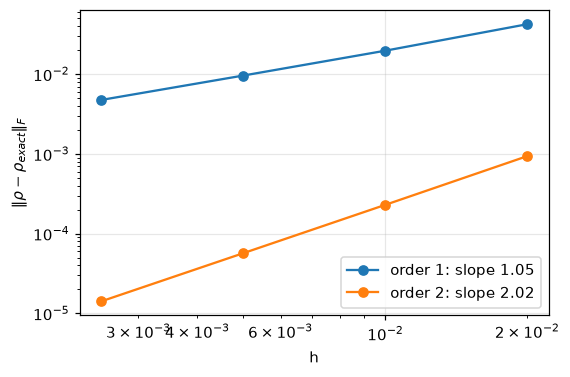

In [5]:
N = 20; a = dr.destroy(N); ad = a.conj().T
H = 0.3 * ad @ a + 0.05 * ad @ ad @ a @ a + 0.4 * (a + ad)
Ls = [np.sqrt(0.5) * a, np.sqrt(0.1) * ad @ a]
psi0 = dr.coherent(N, 1.2); T = 2.0
rex = dr.exact_rho(np.outer(psi0, psi0.conj()), H, Ls, T)
He = dr.heff(H, Ls)
hs = [0.02, 0.01, 0.005, 0.0025]
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for order in (1, 2):
    errs = []
    for h in hs:
        st = dr.Purified.from_ket(psi0)
        for _ in range(int(round(T / h))):
            dr.kraus_step(st, He, Ls, h, order=order, rtol=1e-12)
        errs.append(np.linalg.norm(st.rho() - rex))
    slope = np.polyfit(np.log(hs), np.log(errs), 1)[0]
    ax.loglog(hs, errs, "o-", label=f"order {order}: slope {slope:.2f}")
ax.set(xlabel="h", ylabel=r"$\|\rho-\rho_{exact}\|_F$"); ax.legend(); plt.show()

## 5. Stability and the trace-defect diagnostic

$U$ and $U'$ are truncated Taylor series, so a component of energy $E$ is amplified by $|1-ihE-h^2E^2/2|^2=1+(hE)^4/4$ per step. The cheapest guard is the trace *before* renormalisation, $\mathrm{Tr}\,\mathcal K(\rho)-1=O(h^3)$: log it every step.

||H_eff||_2 = 32.7


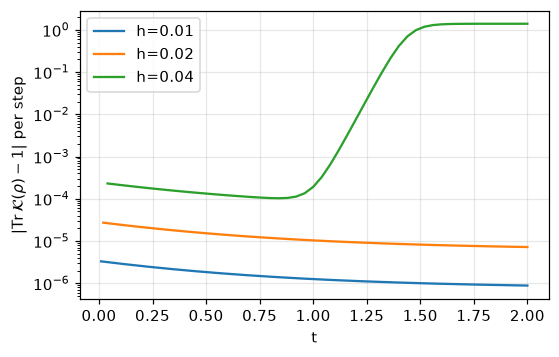

In [6]:
def run_with_defect(h, nsteps):
    st = dr.Purified.from_ket(psi0); defects = []
    for _ in range(nsteps):
        P = st.Psi
        dr.kraus_step(st, He, Ls, h, order=2, rtol=1e-12)
        # recompute the un-normalised trace of the same step for logging
        st2 = dr.Purified(P.copy()); Pn = st2.Psi
        P1 = He @ Pn; X = Pn - 1j*h*P1
        blocks = [X - 0.5*h*h*(He @ P1)]
        for L in Ls:
            Y = L @ Pn
            blocks += [np.sqrt(h/2)*(Y - 1j*h*(He @ Y)), np.sqrt(h/2)*(L @ X)]
        blocks += [h/np.sqrt(2)*(Lj @ (Lk @ Pn)) for Lj in Ls for Lk in Ls]
        defects.append(abs(sum(np.vdot(B, B).real for B in blocks) - 1))
        if not np.isfinite(defects[-1]) or defects[-1] > 1e3:
            break
    return np.array(defects)

print("||H_eff||_2 =", round(np.linalg.norm(He, 2), 1))
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for h in (0.01, 0.02, 0.04):
    d = run_with_defect(h, int(round(T / h)))
    ax.semilogy(np.arange(1, len(d) + 1) * h, d, label=f"h={h}")
ax.set(xlabel="t", ylabel=r"$|\mathrm{Tr}\,\mathcal{K}(\rho)-1|$ per step"); ax.legend(); plt.show()

At $h=0.04$ the defect grows step after step and the run blows up; at $h\le 0.02$ it stays at the $O(h^3)$ level. In the QTT solver this check costs one norm per step.

## 6. Truncating $\mu$: a cat state under dephasing

Two-photon-stabilised cat, single mode for clarity: $L_2=\sqrt{\kappa_2}(a^2-\alpha^2)$ plus dephasing $L_\varphi=\sqrt{\kappa_\varphi}\,a^\dagger a$. Dephasing mixes the state; $\chi_\mu$ follows $1/\mathrm{Tr}\rho^2$ at fixed tolerance.

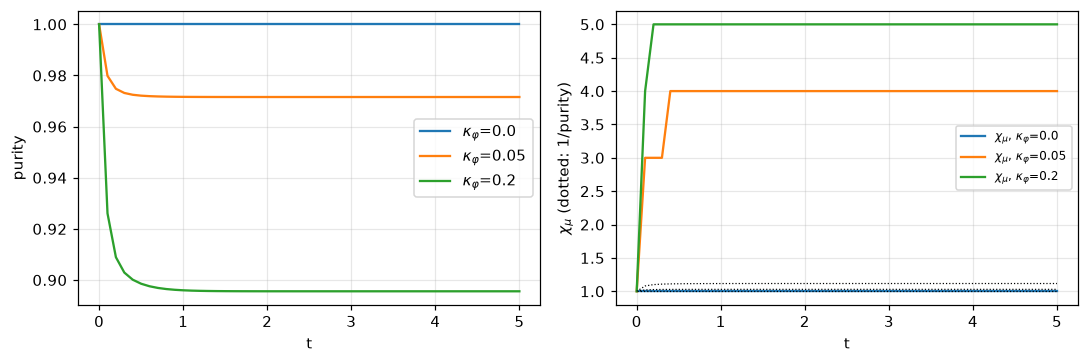

In [7]:
N = 32; a = dr.destroy(N); alpha = 2.0
res = {}
for kphi in (0.0, 0.05, 0.2):
    Ls2 = [np.sqrt(1.0) * (a @ a - alpha**2 * np.eye(N))]
    if kphi: Ls2.append(np.sqrt(kphi) * a.conj().T @ a)
    res[kphi] = dr.evolve(dr.cat(N, alpha, +1), np.zeros((N, N)), Ls2, t_final=5.0, h=2e-3, every=50, rtol=1e-6)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for k, r in res.items():
    ax[0].plot(r.times, r.purity, label=rf"$\kappa_\varphi$={k}")
    ax[1].plot(r.times, r.chi_mu, label=rf"$\chi_\mu$, $\kappa_\varphi$={k}")
    ax[1].plot(r.times, 1 / r.purity, "k:", lw=0.8)
ax[0].set(xlabel="t", ylabel="purity"); ax[0].legend()
ax[1].set(xlabel="t", ylabel=r"$\chi_\mu$ (dotted: 1/purity)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

$\chi_\mu$ is set by the tolerance, so it exceeds $1/\mathrm{Tr}\rho^2$ (which only counts the dominant weights), but it tracks the same trend and stays far below $N=32$.

## 7. Same run through `qttlind`

In [8]:
if HAVE_QTTLIND:
    sysq = ql.System(); m = sysq.add_mode("cav", bits=5)
    Lq = [np.sqrt(1.0) * (m**2 - alpha**2), np.sqrt(0.2) * m.n()]
    sol = ql.LindbladSolver(sysq, 0 * m.n(), Lq, scheme="kraus2", dt=2e-3, tol=1e-6)
    rq = sol.run(sysq.product_state(cav=ql.states.cat(alpha, parity=+1)), t_final=5.0, every=50,
                 track=["purity", "chi_mu"])
    print("max |purity_qtt - purity_oracle| =", np.abs(np.array(rq.track["purity"]) - res[0.2].purity).max())
else:
    print("QTT solver not implemented yet (see qttlind.FEATURES): comparison skipped.")

max |purity_qtt - purity_oracle| = 0.0003168514837623704
